The Extended Kalman Filter (EKF) equations mirror the standard Kalman Filter (KF) equations because covariance updates and gain calculations depend exclusively on error dynamics, where the non-linear zero-th order terms cancel out when subtracting mean predictions, leaving a system of linear error dynamics governed by the Jacobians $F$ and $H$

### State Prediction Step
Consider a non-linear process model:
$$x_k = f(x_{k-1}, u_{k-1}) + w_{k-1}, \quad w_{k-1} \sim \mathcal{N}(0, Q_{k-1})$$

Expand $f(x_{k-1}, u_{k-1})$ using a first-order Taylor series around the previous state estimate $\hat{x}_{k-1\vert{}k-1}$:

$$f(x_{k-1}, u_{k-1}) \approx f(\hat{x}_{k-1\vert{}k-1}, u_{k-1}) + F_{k-1} (x_{k-1} - \hat{x}_{k-1\vert{}k-1})$$
where the Jacobian matrix $F_{k-1}$ is defined as:
$$F_{k-1} = \left. \frac{\partial f}{\partial x} \right\vert{}_{\hat{x}_{k-1\vert{}k-1}, u_{k-1}}$$

#### Mean State Propagation
The predicted state estimate $\hat{x}_{k\vert{}k-1}$ is evaluated directly through the non-linear function:
$$\hat{x}_{k\vert{}k-1} = \mathbb{E}[x_k] \approx f(\hat{x}_{k-1\vert{}k-1}, u_{k-1})$$

#### Error State Cancellation
Define the state estimation error as $\delta x = x - \hat{x}$. 
Subtracting the predicted mean $\hat{x}_{k\vert{}k-1}$ from the actual state $x_k$ gives:
$$\delta x_{k\vert{}k-1} = x_k - \hat{x}_{k\vert{}k-1}$$
$$\delta x_{k\vert{}k-1} \approx \Big( f(\hat{x}_{k-1\vert{}k-1}, u_{k-1}) + F_{k-1} \delta x_{k-1\vert{}k-1} + w_{k-1} \Big) - f(\hat{x}_{k-1\vert{}k-1}, u_{k-1})$$

The non-linear term $f(\hat{x}_{k-1\vert{}k-1}, u_{k-1})$ subtracts out completely:
$$\delta x_{k\vert{}k-1} = F_{k-1} \delta x_{k-1\vert{}k-1} + w_{k-1}$$

#### Covariance Propagation
Because the error state $\delta x_{k\vert{}k-1}$ follows a purely linear equation in terms of $\delta x_{k-1\vert{}k-1}$, taking its expectation yields the exact KF covariance form:
$$P_{k\vert{}k-1} = \mathbb{E}[\delta x_{k\vert{}k-1} \delta x_{k\vert{}k-1}^T] = F_{k-1} \mathbb{E}[\delta x_{k-1\vert{}k-1} \delta x_{k-1\vert{}k-1}^T] F_{k-1}^T + \mathbb{E}[w_{k-1} w_{k-1}^T]$$
$$P_{k\vert{}k-1} = F_{k-1} P_{k-1\vert{}k-1} F_{k-1}^T + Q_{k-1}$$

### Measurement Update Step
Consider a non-linear measurement model:
$$z_k = h(x_k) + v_k, \quad v_k \sim \mathcal{N}(0, R_k)$$
Expand $h(x_k)$ around the predicted state $\hat{x}_{k\vert{}k-1}$:
$$h(x_k) \approx h(\hat{x}_{k\vert{}k-1}) + H_k (x_k - \hat{x}_{k\vert{}k-1})$$
where the Jacobian matrix $H_k$ is:
$$H_k = \left. \frac{\partial h}{\partial x} \right\vert{}_{\hat{x}_{k\vert{}k-1}}$$

#### Predicted Measurement & Innovation Cancellation
The predicted measurement is $\hat{z}_k = h(\hat{x}_{k\vert{}k-1})$. 
The measurement residual (innovation) $y_k$ is calculated as:
$$y_k = z_k - \hat{z}_k$$
$$y_k \approx \Big( h(\hat{x}_{k\vert{}k-1}) + H_k \delta x_{k\vert{}k-1} + v_k \Big) - h(\hat{x}_{k\vert{}k-1})$$

The non-linear term $h(\hat{x}_{k\vert{}k-1})$ cancels out completely:
$$y_k = H_k \delta x_{k\vert{}k-1} + v_k$$

#### Innovation Covariance & Kalman Gain
Because the innovation vector $y_k$ is linear with respect to the error state $\delta x_{k\vert{}k-1}$, calculating the innovation covariance $S_k$ yields:
$$S_k = \mathbb{E}[y_k y_k^T] = H_k \mathbb{E}[\delta x_{k\vert{}k-1} \delta x_{k\vert{}k-1}^T] H_k^T + \mathbb{E}[v_k v_k^T] = H_k P_{k\vert{}k-1} H_k^T + R_k$$

The optimal gain $K_k$ minimizes the posterior error covariance, which depends only on the cross-covariance between state error and measurement error ($\mathbb{E}[\delta x_{k\vert{}k-1} y_k^T] = P_{k\vert{}k-1} H_k^T$):
$$K_k = P_{k\vert{}k-1} H_k^T S_k^{-1}$$

### Key takeaways
The EKF does not run Kalman filtering on the state $x$; it runs standard Kalman filtering on the error state $\delta x$.

Once we shift focus from the state $x$ to the error $\delta x$, the math reveals two distinct, parallel tracks running inside the filter:
1. **The Mean Track (Non-linear)**:
The mean estimate $\hat{x}$ moves along the full curved trajectory via $f(\hat{x})$ and $h(\hat{x})$. 
No linearization is used to propagate the state mean itself.
2. **The Error Track (Linear)**:
The perturbation $\delta x$ lives in the local tangent space around that mean.
Subtracting the predicted mean cancels the zero-th order non-linear baseline, leaving a purely linear state-space model for the error:
$$\delta x_{k\vert{}k-1} \approx F_{k-1} \delta x_{k-1\vert{}k-1} + w_{k-1}$$

Because $\delta x$ follows a standard linear state equation governed by $F_{k-1}$, taking the expectation $\mathbb{E}[\delta x \delta x^T]$ requires no new machinery. The entire uncertainty pipeline (covariance propagation $P$, innovation covariance $S$, and optimal gain $K$) is identical to the LKF.

## Implementing the aircraft example

In the LKF, we implemented this example to estimate range and velocity from exactly these measurements (1D case). Now we will move on to 2D, by estimating $(p_x, p_y, v_x, v_y)$ from $(r, v_r)$.

1. Simulate an aircraft Ground truth trajectory (actual 2D coordinates)
2. Add gaussian noise (governed by mean and stdev) to them to obtain measurement and standard deviation.
3. Simulate some steps

For now, we will restrict the problem and assume constant velocity. This makes the state transition function $F$ linear:
$$p_x = p_x + v_x * dt$$
$$p_y = p_y + v_y * dt$$
$$v_x = v_{x_0}$$
$$v_y = v_{y_0}$$

and the whole prediction part reamains as a standard LKF.

- **The Initial Error Covariance Matrix $P$** represents the initial uncertainty for each state and how they correlate. Off-diagonal elements can start at $0$ because the initial errors are assumed to be independent.
$$P_0 = \begin{bmatrix} \sigma_{px}^2 & 0 & 0 & 0 \\  0 & \sigma_{py}^2 & 0 & 0 \\  0 & 0 & \sigma_{vx}^2 & 0 \\  0 & 0 & 0 & \sigma_{vy}^2 \end{bmatrix}$$

- **The Process Noise Matrix ($Q$)** (Continuous White Noise Acceleration Model)
Just like in the 1D LKF model, $Q$ accounts for unmodeled physical disturbances (like sudden winds or minor throttle adjustments). 
In 2D, the model white noise acceleration ($\sigma_a^2$) acts independently along the $x$ and $y$ axes.
$$Q = \begin{bmatrix} \frac{1}{4}\Delta t^4 \sigma_{ax}^2 & 0 & \frac{1}{2}\Delta t^3 \sigma_{ax}^2 & 0 \\  0 & \frac{1}{4}\Delta t^4 \sigma_{ay}^2 & 0 & \frac{1}{2}\Delta t^3 \sigma_{ay}^2 \\  \frac{1}{2}\Delta t^3 \sigma_{ax}^2 & 0 & \Delta t^2 \sigma_{ax}^2 & 0 \\  0 & \frac{1}{2}\Delta t^3 \sigma_{ay}^2 & 0 & \Delta t^2 \sigma_{ay}^2 \end{bmatrix}$$

Assuming isotropic noise: If the target's maneuvers are equally likely in any direction, we can set $\sigma_{ax}^2 = \sigma_{ay}^2 = \sigma_a^2$.

The part that will be non-linear is the $H$, because it has to map measurements of $r$, $v_r$ to our state $p_x, p_y, v_x, v_y$.

- $r$ is the distance from the radar to the aircraft:
$$r = \sqrt{p_x^{2} + p_y^{2}}$$
- $v_r$ is the radial velocity, that is, the rate of change of the distance of the aircraft to the radar
$$v_r = \frac{\partial r}{\partial t} = \frac{\frac{\partial}{\partial t} (p_x^2 + p_y^2)}{\sqrt{p_x^2 + p_y^2}} = \frac{p_x v_x + p_y v_y}{\sqrt{p_x^2 + p_y^2}}$$
where $\frac{dp_x}{dt} = v_x$ and $\frac{dp_y}{dt} = v_y$ 
$\qquad \rightarrow \qquad$ 
$\frac{\partial p_x^2}{\partial t} = 2p_x \cdot \frac{dp_x}{dt}$ and $\frac{\partial p_y^2}{\partial t} = 2p_y \cdot \frac{dp_y}{dt}$

Finally,
$$h(x) = \begin{bmatrix} r \\ v_r \end{bmatrix} = \begin{bmatrix} \sqrt{p_x^2 + p_y^2} \\ \frac{p_x v_x + p_y v_y}{\sqrt{p_x^2 + p_y^2}} \end{bmatrix}$$

Now we need to compute the Jacobian $H$, which will be evaluated at $\hat{x}_{k,k-1}$ at each time step:

$$H = \begin{bmatrix} \frac{\partial r}{\partial p_x} & \frac{\partial r}{\partial p_y} & \frac{\partial r}{\partial v_x} & \frac{\partial r}{\partial v_y} \\ \frac{\partial v_r}{\partial p_x} & \frac{\partial v_r}{\partial p_y} & \frac{\partial v_r}{\partial v_x} & \frac{\partial v_r}{\partial v_y} \end{bmatrix} = \begin{bmatrix} \frac{p_x}{\sqrt{p_x^2 + p_y^2}} & \frac{p_y}{\sqrt{p_x^2 + p_y^2}} & 0 & 0 \\ \frac{v_x r^2 - p_x(p_x v_x + p_y v_y)}{r^3} & \frac{v_y r^2 - p_y(p_x v_x + p_y v_y)}{r^3} & \frac{p_x}{r} & \frac{p_y}{r} \end{bmatrix}$$

In [112]:
import numpy as np
import matplotlib.pyplot as plt

In [113]:
dt = 0.1
sigma_px = 30
sigma_py = 30
sigma_vx = 5
sigma_vy = 5

sigma_a = 0.5
sigma_ax = sigma_a
sigma_ay = sigma_a

px0 = -500
py0 = -500
vx0 = 800
vy0 = 50

sigma_r = 30
sigma_vr = 10

In [114]:
class SemiEKF:
    """Not a full EKF since the model dynamics themselves are linear, thus the prediction step remains the same as an LKF. 
    The EKF part is only the H jacobian in this case"""

    def __init__(self):
        self.x = np.array([[px0], [py0], [vx0], [vy0]])
        self.F = np.array([[1, 0, dt, 0], [0, 1, 0, dt], [0, 0, 1, 0], [0, 0, 0, 1]])
        self.P = np.diag([sigma_px**2, sigma_py**2, sigma_vx**2, sigma_vy**2])
        self.Q = np.array([
            [1/4 * dt**4 * sigma_ax**2, 0, 1/2 * dt**3 * sigma_ax**2, 0],
            [0, 1/4 * dt**4 * sigma_ay**2, 0, 1/2 * dt**3 * sigma_ay**2],
            [1/2 * dt**3 * sigma_ax*2, 0, dt**2 * sigma_ax**2, 0],
            [0, 1/2 * dt**3 * sigma_ay**2, 0, dt**2 * sigma_ay**2],
        ])
        self.R = np.diag([sigma_r**2, sigma_vr**2])

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, z: np.ndarray):
        px, py, vx, vy = self.x[0,0], self.x[1,0], self.x[2,0], self.x[3,0]
        r = np.sqrt(px**2 + py**2)
        vr = (px * vx + py * vy) / r
        h_x = np.array([[r], [vr]]) # Predicted measurement vector [r; v_r]

        # evaluate H at prediction x_k,k-1
        H = np.array([
            [px/r, py/r, 0, 0], 
            [(vx*r**2-px*(px*vx+py*vy))/r**3, (vy*r**2-py*(px*vx+py*vy))/r**3, px/r, py/r]
        ])

        S = H @ self.P @ H.T
        S = S + self.R
        K = self.P @ H.T @ np.linalg.inv(S)
        
        self.x = self.x + K @ (z - h_x)

        self.P = (np.identity(4) - K @ H) @ self.P
        
        return self.x

#### Simple test: Straight line constant velocity

In [115]:
t = np.arange(0, 5.0, dt)
N = len(t)

gt_px = px0 + vx0 * t
gt_py = py0 + vy0 * t
gt_vx = np.ones(N) * vx0
gt_vy = np.ones(N) * vy0

gt_r = np.sqrt(gt_px**2 + gt_py**2)
gt_vr = (gt_px * gt_vx + gt_py * gt_vy ) / gt_r

obs_r = gt_r + np.random.normal(0, sigma_r, N)
obs_vr = gt_vr + np.random.normal(0, sigma_vr, N)

In [116]:
kf = SemiEKF()

kf_px = np.zeros(N)
kf_py = np.zeros(N)
kf_vx = np.zeros(N)
kf_vy = np.zeros(N)

kf_r = np.zeros(N)
kf_vr = np.zeros(N)

for i in range(N):
    kf.predict()
    obs = np.array([[obs_r[i]], [obs_vr[i]]])
    x_hat = kf.update(obs)
    kf_px[i] = x_hat[0][0]
    kf_py[i] = x_hat[1][0]
    kf_vx[i] = x_hat[2][0]
    kf_vy[i] = x_hat[3][0]

    # Compute what the EKF predicted in polar space for this step
    r_pred = np.sqrt(x_hat[0,0]**2 + x_hat[1,0]**2)
    vr_pred = (x_hat[0,0]*x_hat[2,0] + x_hat[1,0]*x_hat[3,0]) / r_pred
    kf_r[i] = r_pred
    kf_vr[i] = vr_pred


<>:46: SyntaxWarning: invalid escape sequence '\_'
<>:47: SyntaxWarning: invalid escape sequence '\_'
<>:50: SyntaxWarning: invalid escape sequence '\_'
<>:51: SyntaxWarning: invalid escape sequence '\_'
<>:46: SyntaxWarning: invalid escape sequence '\_'
<>:47: SyntaxWarning: invalid escape sequence '\_'
<>:50: SyntaxWarning: invalid escape sequence '\_'
<>:51: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_15335/3238035165.py:46: SyntaxWarning: invalid escape sequence '\_'
  l1 = axes[3].plot(t, gt_r, 'k-', linewidth=2, label='True Range ($gt\_r$)')
/tmp/ipykernel_15335/3238035165.py:47: SyntaxWarning: invalid escape sequence '\_'
  l2 = ax4_twin.plot(t, gt_vr, 'g-', linewidth=2, label='True Radial Vel ($gt\_vr$)')
/tmp/ipykernel_15335/3238035165.py:50: SyntaxWarning: invalid escape sequence '\_'
  l3 = axes[3].plot(t, obs_r, 'orange', alpha=0.4, linestyle='--', label='Observed Range ($obs\_r$)')
/tmp/ipykernel_15335/3238035165.py:51: SyntaxWarning: invalid escape sequence

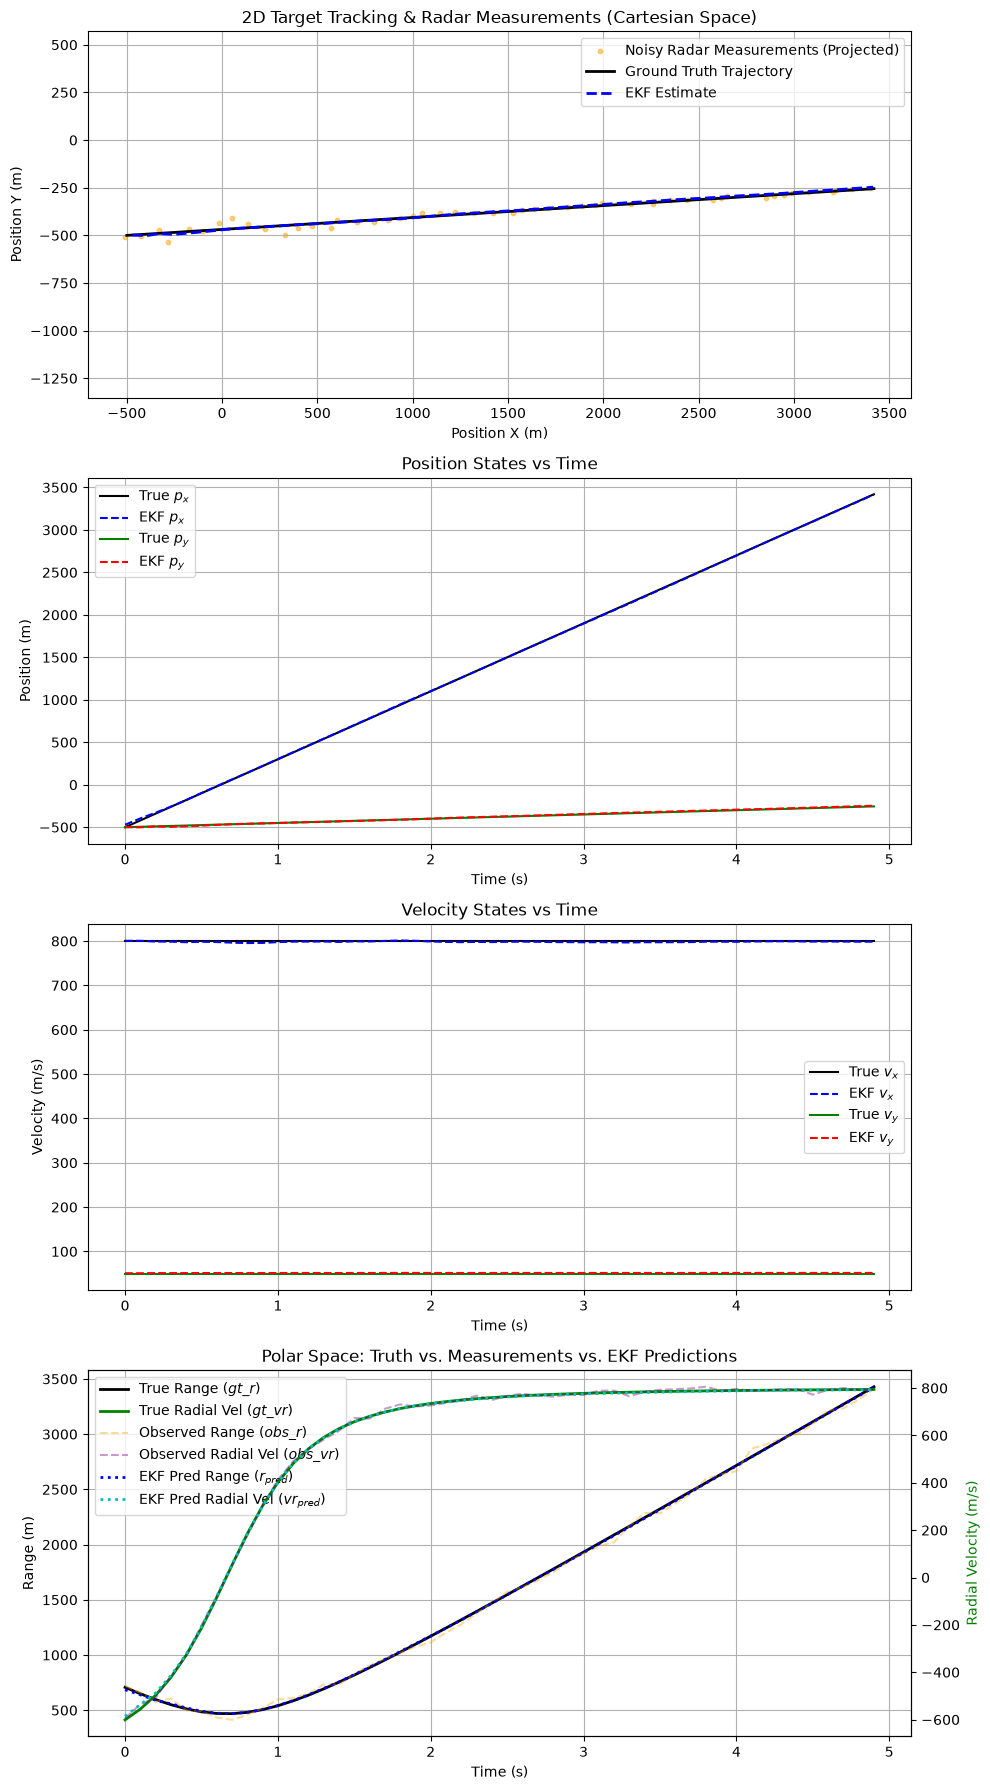

In [117]:
def plot():
    fig, axes = plt.subplots(4, 1, figsize=(10, 18))

    # Convert Polar Observations to Cartesian for 2D Plot Visualization
    gt_theta = np.arctan2(gt_py, gt_px)
    obs_px = obs_r * np.cos(gt_theta)
    obs_py = obs_r * np.sin(gt_theta)

    # Plot 1: 2D Cartesian Trajectory (X vs Y) with Measurements
    axes[0].scatter(obs_px, obs_py, c='orange', s=10, alpha=0.5, label='Noisy Radar Measurements (Projected)')
    axes[0].plot(gt_px, gt_py, 'k-', label='Ground Truth Trajectory', linewidth=2)
    axes[0].plot(kf_px, kf_py, 'b--', label='EKF Estimate', linewidth=2)
    axes[0].set_title('2D Target Tracking & Radar Measurements (Cartesian Space)')
    axes[0].set_xlabel('Position X (m)')
    axes[0].set_ylabel('Position Y (m)')
    axes[0].grid(True)
    axes[0].legend()
    axes[0].axis('equal')

    # Plot 2: Position Components over Time
    axes[1].plot(t, gt_px, 'k-', label='True $p_x$', linewidth=1.5)
    axes[1].plot(t, kf_px, 'b--', label='EKF $p_x$', linewidth=1.5)
    axes[1].plot(t, gt_py, 'g-', label='True $p_y$', linewidth=1.5)
    axes[1].plot(t, kf_py, 'r--', label='EKF $p_y$', linewidth=1.5)
    axes[1].set_title('Position States vs Time')
    axes[1].set_xlabel('Time (s)')
    axes[1].set_ylabel('Position (m)')
    axes[1].grid(True)
    axes[1].legend()

    # Plot 3: Velocity Components over Time
    axes[2].plot(t, gt_vx, 'k-', label='True $v_x$', linewidth=1.5)
    axes[2].plot(t, kf_vx, 'b--', label='EKF $v_x$', linewidth=1.5)
    axes[2].plot(t, gt_vy, 'g-', label='True $v_y$', linewidth=1.5)
    axes[2].plot(t, kf_vy, 'r--', label='EKF $v_y$', linewidth=1.5)
    axes[2].set_title('Velocity States vs Time')
    axes[2].set_xlabel('Time (s)')
    axes[2].set_ylabel('Velocity (m/s)')
    axes[2].grid(True)
    axes[2].legend()

    # Plot 4: Polar Comparison (Ground Truth vs Raw Observations vs EKF Predictions)
    ax4_twin = axes[3].twinx()
    
    # Ground Truth Polar (Solid lines)
    l1 = axes[3].plot(t, gt_r, 'k-', linewidth=2, label='True Range ($gt\_r$)')
    l2 = ax4_twin.plot(t, gt_vr, 'g-', linewidth=2, label='True Radial Vel ($gt\_vr$)')
    
    # Raw Noisy Observations (Dotted/Alpha lines)
    l3 = axes[3].plot(t, obs_r, 'orange', alpha=0.4, linestyle='--', label='Observed Range ($obs\_r$)')
    l4 = ax4_twin.plot(t, obs_vr, 'purple', alpha=0.4, linestyle='--', label='Observed Radial Vel ($obs\_vr$)')

    # EKF Predictions in Polar Space ($h(\hat{x})$)
    l5 = axes[3].plot(t, kf_r, 'b:', linewidth=2, label='EKF Pred Range ($r_{pred}$)')
    l6 = ax4_twin.plot(t, kf_vr, 'c:', linewidth=2, label='EKF Pred Radial Vel ($vr_{pred}$)')
    
    axes[3].set_title('Polar Space: Truth vs. Measurements vs. EKF Predictions')
    axes[3].set_xlabel('Time (s)')
    axes[3].set_ylabel('Range (m)', color='black')
    ax4_twin.set_ylabel('Radial Velocity (m/s)', color='green')
    axes[3].grid(True)
    
    # Combined legend for twin axes
    lines = l1 + l2 + l3 + l4 + l5 + l6
    labels = [l.get_label() for l in lines]
    axes[3].legend(lines, labels, loc='upper left')

    plt.tight_layout()
    plt.show()

plot()

The estimates look almost perfect. Let's see what happens with a more complex trajectory

#### Non-constant velocity trajectory

In [118]:
dt = 0.1
t = np.arange(0, 20.0, dt)
N = len(t)

sigma_px = 30
sigma_py = 30
sigma_vx = 5
sigma_vy = 5

sigma_a = 5.0
sigma_ax = sigma_a
sigma_ay = sigma_a

px0 = -500
py0 = -500
vx0 = 800
vy0 = 50

sigma_r = 30
sigma_vr = 10

gt_px = np.zeros(N)
gt_py = np.zeros(N)
gt_vx = np.zeros(N)
gt_vy = np.zeros(N)

curr_px, curr_py = px0, py0
curr_vx, curr_vy = vx0, vy0

for i in range(N):
    current_time = t[i]
    
    # sudden maneuver/turn between t = 5s and t = 10s
    if 5.0 <= current_time <= 10.0:
        acc_x = -30.0  # decelerate in x
        acc_y = 80.0   # Sharp turn in y
    else:
        acc_x = 0.0
        acc_y = 0.0
        
    if i > 0:
        curr_vx += acc_x * dt
        curr_vy += acc_y * dt
        curr_px += curr_vx * dt
        curr_py += curr_vy * dt
        
    gt_px[i] = curr_px
    gt_py[i] = curr_py
    gt_vx[i] = curr_vx
    gt_vy[i] = curr_vy

# calculate the true polar measurements and add sensor noise
gt_r = np.sqrt(gt_px**2 + gt_py**2)
gt_vr = (gt_px * gt_vx + gt_py * gt_vy) / gt_r

obs_r = gt_r + np.random.normal(0, sigma_r, N)
obs_vr = gt_vr + np.random.normal(0, sigma_vr, N)

In [119]:
kf = SemiEKF()

kf_px = np.zeros(N)
kf_py = np.zeros(N)
kf_vx = np.zeros(N)
kf_vy = np.zeros(N)

kf_r = np.zeros(N)
kf_vr = np.zeros(N)

for i in range(N):
    kf.predict()
    obs = np.array([[obs_r[i]], [obs_vr[i]]])
    x_hat = kf.update(obs)
    kf_px[i] = x_hat[0][0]
    kf_py[i] = x_hat[1][0]
    kf_vx[i] = x_hat[2][0]
    kf_vy[i] = x_hat[3][0]

    # Compute what the EKF predicted in polar space for this step
    r_pred = np.sqrt(x_hat[0,0]**2 + x_hat[1,0]**2)
    vr_pred = (x_hat[0,0]*x_hat[2,0] + x_hat[1,0]*x_hat[3,0]) / r_pred
    kf_r[i] = r_pred
    kf_vr[i] = vr_pred

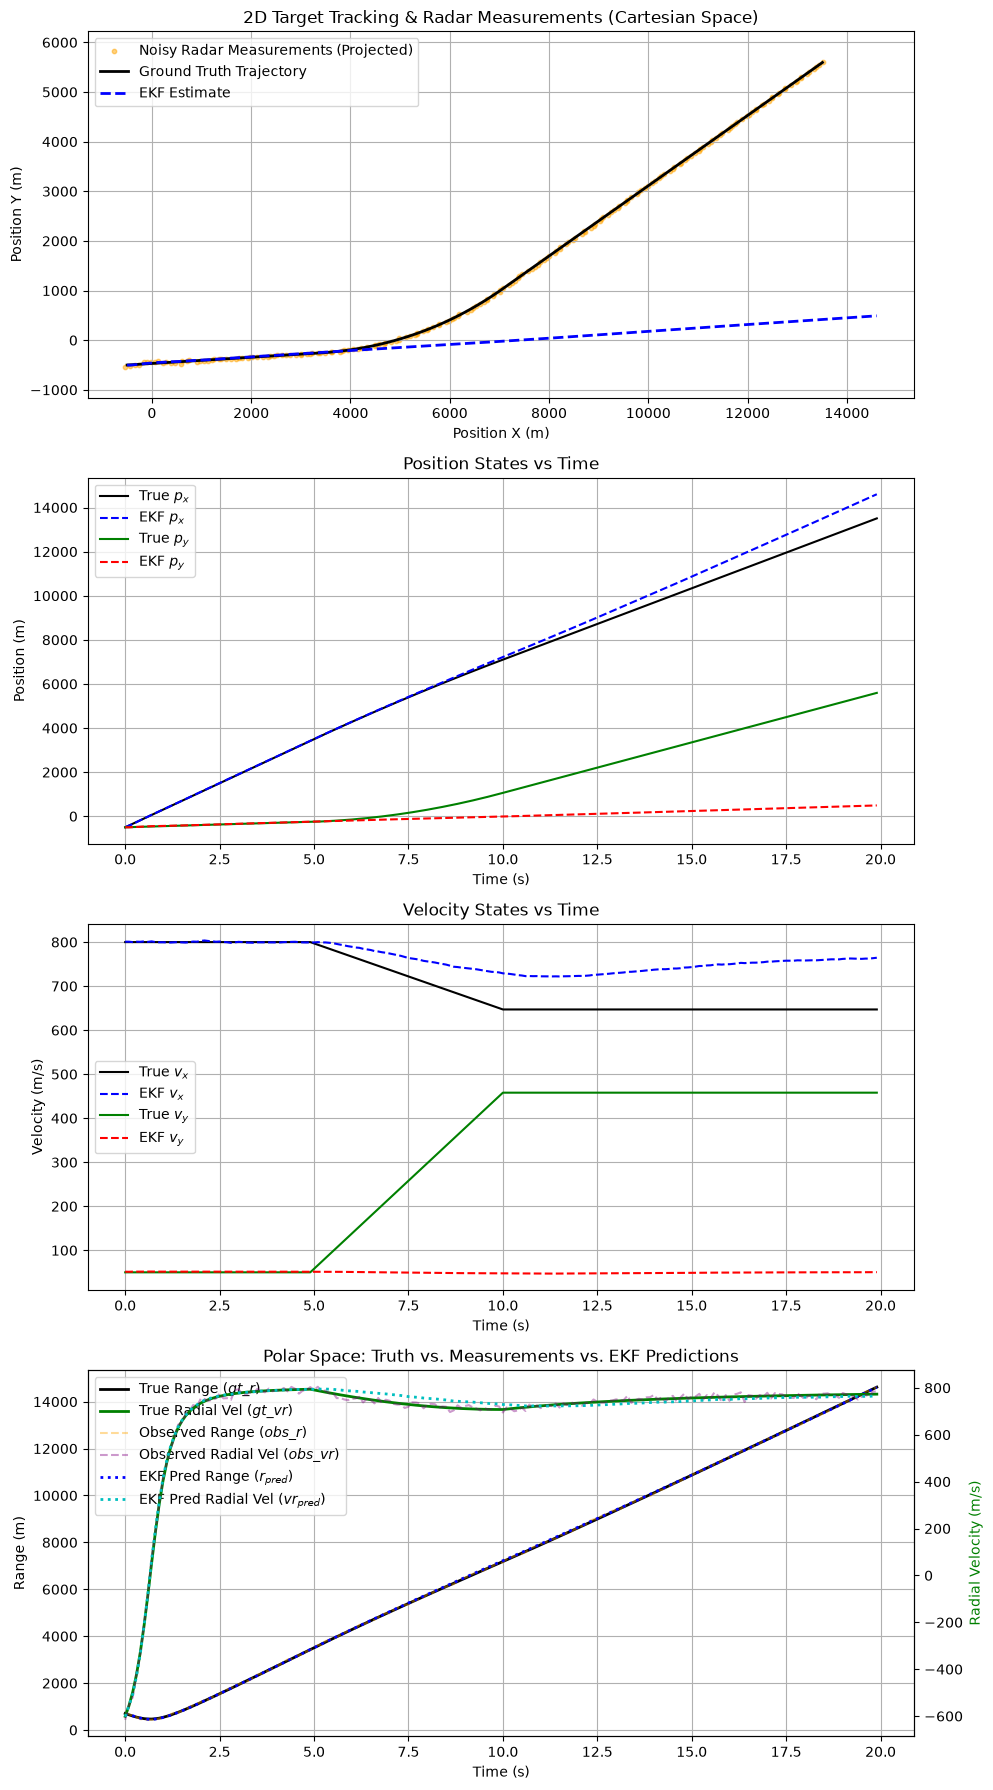

In [120]:
plot()

The EKF's estimations are off. Although it tracks range and radial velocity correctly. 

#### Why?
We are trying to estimate 2D position from range and radial velocity only, thus we have insufficient information as to where the aircraft will be. There are infinite plausible positions (in a circle) that the aircraft will be in if we only know how far it is from us. At any single snapshot in time, a single range measurement $r = \sqrt{p_x^2 + p_y^2}$ tells the filter: "The target lies somewhere on a 2D circle of radius $r$ around the radar." It provides zero information about where on that circle the target is.

So the problem is impossible to solve. Let's add the Bearing to the measurements, which provides the angle at which the aircraft is from the radar's perspective.